# 동일 조건 반복 오버랩 실험

라플라스 노이즈의 랜덤성 때문에 한 번의 시행에 의존하지 않고, 동일한 실험 조건에서 반복 시행한다. 각 시행은 원 논문의 상대폭–streak 중단 규칙으로 자체적인 `k_stop`을 찾는다.

기본 조건: `eps=0.5`, `threshold=0.01`, `streak_required=5`, `reps=10`, `maxq=500`.

각 시행의 최종 `k_stop`, 신뢰구간 절대폭 `W`, 오버랩 비율 `r`을 저장하고, 데이터셋별로 평균·중앙값·최소–최대·표준편차·사분위 범위를 요약한다. `maxq`는 반복을 끝내기 위한 연구 조건이 아니라 안전상 상한이며, 상한에 도달하면 오류로 처리한다.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.22,
})

ALPHA = 0.05
EPS = 0.5
THRESHOLD = 0.01
STREAK_REQUIRED = 5
REPS = 10
MAXQ = 500
SEED0 = 2026

DATASETS = {
    "CardBase": {"path": Path("data/CardBase.csv"), "column": "Credit_Limit"},
    "Bank": {"path": Path("data/bank_exp.parquet"), "column": "credit_limit"},
}
OUTPUT_DIR = Path("outputs/dp_overlap_repeated")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
def load_numeric(path, column):
    path = Path(path)
    df = pd.read_csv(path) if path.suffix.lower() == ".csv" else pd.read_parquet(path)
    if column not in df.columns:
        raise KeyError(f"{path}에 {column!r} 열이 없습니다.")
    x = pd.to_numeric(df[column], errors="coerce").dropna().to_numpy(float)
    if len(x) == 0: raise ValueError(f"{path}의 {column!r}에 유효한 값이 없습니다.")
    n = len(x)
    return {"x": x, "n": n, "true_mean": float(x.mean()),
            "delta": float((x.max() - x.min()) / n),
            "min": float(x.min()), "max": float(x.max())}

DATA = {name: load_numeric(cfg["path"], cfg["column"])
        for name, cfg in DATASETS.items()}
pd.DataFrame([{"dataset": n, **{k:v for k,v in d.items() if k != "x"}}
              for n,d in DATA.items()])

,dataset,n,true_mean,delta,min,max
0,CardBase,500,252614.000000,1794.000000,2000.0,899000.0
1,Bank,6744,9074.479537,4.904656,1439.0,34516.0


In [3]:
def overlap_metrics(ci_lo, ci_hi, delta):
    # 최대값 레코드 제거 방향: 원본 수렴점 구간을 -delta만큼 이동
    adj_lo, adj_hi = ci_lo - delta, ci_hi - delta
    overlap_lo, overlap_hi = max(ci_lo, adj_lo), min(ci_hi, adj_hi)
    overlap_width = max(0.0, overlap_hi - overlap_lo)
    width = ci_hi - ci_lo
    return {
        "adj_center_shift": -delta, "adj_ci_lo": adj_lo, "adj_ci_hi": adj_hi,
        "overlap_lo": overlap_lo, "overlap_hi": overlap_hi,
        "overlap_width": overlap_width,
        "overlap_ratio": overlap_width / width if width > 0 else np.nan,
        "width_to_delta": width / delta if delta > 0 else np.nan,
    }

def run_one(data, eps=EPS, threshold=THRESHOLD, streak_required=STREAK_REQUIRED,
            maxq=MAXQ, seed=0):
    rng = np.random.default_rng(seed)
    b = data["delta"] / eps
    responses, rows, streak = [], [], 0

    for k in range(1, maxq + 1):
        response = float(data["true_mean"] + rng.laplace(0.0, b))
        responses.append(response)
        a = np.asarray(responses)
        mean = float(a.mean())
        if k < 2:
            std = moe = ci_lo = ci_hi = width = relw = np.nan
            hit = False
        else:
            std = float(a.std(ddof=1))
            se = std / np.sqrt(k)
            moe = float(stats.t.ppf(1 - ALPHA/2, k-1) * se)
            ci_lo, ci_hi = mean - moe, mean + moe
            width = float(2 * moe)
            relw = float(width / abs(mean)) if mean != 0 else np.inf
            hit = relw < threshold
        streak = streak + 1 if hit else 0
        rows.append({"k": k, "response": response, "mean": mean, "std": std,
                     "moe": moe, "ci_lo": ci_lo, "ci_hi": ci_hi,
                     "width": width, "relative_width": relw, "streak": streak, "hit": hit})
        if streak >= streak_required:
            h = pd.DataFrame(rows)
            f = h.iloc[-1].to_dict()
            f.update({"k_stop": int(k), "eps": eps, "eps_total": eps*k,
                      "threshold": threshold, "streak_required": streak_required,
                      "n": data["n"], "delta": data["delta"],
                      "laplace_scale": b, "true_mean": data["true_mean"],
                      "mean_error": f["mean"] - data["true_mean"],
                      "coverage": bool(f["ci_lo"] <= data["true_mean"] <= f["ci_hi"])})
            f.update(overlap_metrics(f["ci_lo"], f["ci_hi"], data["delta"]))
            return h, f
    raise RuntimeError(f"seed={seed}: maxq={maxq} 안에 수렴 조건을 만족하지 못했습니다.")

In [4]:
def run_repeated_same_condition(data_dict, eps=EPS, threshold=THRESHOLD,
                                  streak_required=STREAK_REQUIRED, reps=REPS,
                                  maxq=MAXQ, seed0=SEED0):
    """조건은 고정하고 seed만 바꾸어 데이터셋별 reps회 반복한다."""
    final_rows, trajectory_rows = [], []
    for dataset_i, (name, data) in enumerate(data_dict.items()):
        for rep in range(1, reps + 1):
            seed = seed0 + dataset_i * 100000 + rep
            history, final = run_one(data, eps, threshold, streak_required, maxq, seed)
            final_rows.append({"dataset": name, "rep": rep, "seed": seed, **final})
            h = history.copy()
            h.insert(0, "rep", rep); h.insert(0, "dataset", name); h["seed"] = seed
            trajectory_rows.append(h)
    return pd.DataFrame(final_rows), pd.concat(trajectory_rows, ignore_index=True)

In [5]:
final_results, trajectories = run_repeated_same_condition(
    DATA, eps=EPS, threshold=THRESHOLD, streak_required=STREAK_REQUIRED,
    reps=REPS, maxq=MAXQ, seed0=SEED0
)

final_results.to_csv(OUTPUT_DIR / "final_results.csv", index=False)
trajectories.to_csv(OUTPUT_DIR / "trajectories.csv", index=False)
print("final_results:", final_results.shape, "trajectories:", trajectories.shape)

final_results: (20, 33) trajectories: (779, 14)


In [6]:
def summarize_repeated(final_results):
    metrics = ["k_stop", "width", "relative_width", "overlap_ratio"]
    rows = []
    for name, g in final_results.groupby("dataset", sort=False):
        row = {"dataset": name, "n_reps": len(g)}
        for metric in metrics:
            v = g[metric].to_numpy(float)
            q1, q3 = np.quantile(v, [0.25, 0.75])
            row[f"{metric}_mean"] = v.mean()
            row[f"{metric}_median"] = np.median(v)
            row[f"{metric}_min"] = v.min()
            row[f"{metric}_max"] = v.max()
            row[f"{metric}_std"] = v.std(ddof=1) if len(v) > 1 else np.nan
            row[f"{metric}_q1"] = q1
            row[f"{metric}_q3"] = q3
        rows.append(row)
    return pd.DataFrame(rows)

summary = summarize_repeated(final_results)
summary.to_csv(OUTPUT_DIR / "summary.csv", index=False)
summary[["dataset", "k_stop_mean", "k_stop_median", "k_stop_min", "k_stop_max",
         "width_mean", "width_median", "width_min", "width_max",
         "overlap_ratio_mean", "overlap_ratio_median",
         "overlap_ratio_min", "overlap_ratio_max"]]

,dataset,k_stop_mean,k_stop_median,k_stop_min,k_stop_max,width_mean,width_median,width_min,width_max,overlap_ratio_mean,overlap_ratio_median,overlap_ratio_min,overlap_ratio_max
0,CardBase,71.0,68.5,34.0,100.0,2418.668903,2426.458120,2306.848208,2510.922261,0.257942,0.260648,0.222316,0.285521
1,Bank,6.9,7.0,6.0,9.0,19.109048,18.822077,5.741654,31.754456,0.681619,0.738851,0.145776,0.845544


## Figure 1: 반복 시행 분포

점 하나는 하나의 반복 시행이다. 굵은 점은 중앙값, 가는 선은 최소–최대 범위, 상자는 사분위 범위를 나타낸다. 왼쪽부터 `k_stop`, 신뢰구간 절대폭 `W`, 오버랩 비율 `r`을 비교한다.

In [7]:
def plot_repeated_distributions(final_results, save=None):
    """논문용 수평 interval + raw points Figure. 각 점은 반복 시행이다."""
    metrics = [("k_stop", r"Stopping point $k_{stop}$"),
               ("width", r"Absolute CI width $W$"),
               ("overlap_ratio", r"CI overlap ratio $r$")]
    names = list(final_results["dataset"].drop_duplicates())
    colors = {n:c for n,c in zip(names, ["#2F6DAE", "#D55E4A"])}
    fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.5), constrained_layout=True)
    yloc = np.arange(len(names))[::-1]
    for ax, (metric, label) in zip(axes, metrics):
        for y, name in zip(yloc, names):
            v = final_results.loc[final_results.dataset == name, metric].to_numpy(float)
            color = colors[name]
            q1, med, q3 = np.quantile(v, [0.25, 0.5, 0.75])
            ax.plot([v.min(), v.max()], [y, y], color=color, lw=1.4, alpha=.8, zorder=1)
            ax.plot([q1, q3], [y, y], color=color, lw=9, solid_capstyle="round", zorder=2)
            jitter = np.linspace(-.09, .09, len(v)) if len(v) > 1 else np.array([0.])
            ax.scatter(v, y + jitter, s=32, color=color, edgecolor="white", linewidth=.6,
                       alpha=.9, zorder=3)
            ax.scatter([med], [y], s=64, facecolor="white", edgecolor="black",
                       linewidth=1.1, zorder=4)
            ax.scatter([v.mean()], [y], s=60, marker="D", facecolor="black",
                       edgecolor="white", linewidth=.5, zorder=5)
        ax.set_yticks(yloc, names)
        ax.set_title(label, pad=10, fontweight="bold")
        ax.grid(axis="x", alpha=.25)
        ax.spines["left"].set_visible(False)
        ax.tick_params(axis="y", length=0)
    axes[2].set_xlim(0, 1.05)
    axes[0].set_xlabel("Queries until stopping")
    axes[1].set_xlabel("Width of 95% CI")
    axes[2].set_xlabel("Overlap ratio")
    handles = [plt.Line2D([0],[0], marker="o", color="w", markerfacecolor="#555", label="Individual run", markersize=6),
               plt.Line2D([0],[0], marker="o", color="black", markerfacecolor="white", label="Median", markersize=7),
               plt.Line2D([0],[0], marker="D", color="w", markerfacecolor="black", label="Mean", markersize=7),
               plt.Line2D([0],[0], color="#777", lw=7, label="IQR"),
               plt.Line2D([0],[0], color="#777", lw=1.5, label="Min–max")]
    fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False,
               bbox_to_anchor=(.5, 1.08), fontsize=9)
    fig.suptitle(f"Repeated runs under identical conditions (n={final_results.rep.nunique()} per dataset)",
                 y=1.16, fontsize=14, fontweight="bold")
    if save: fig.savefig(save, bbox_inches="tight")
    plt.show()
    return fig

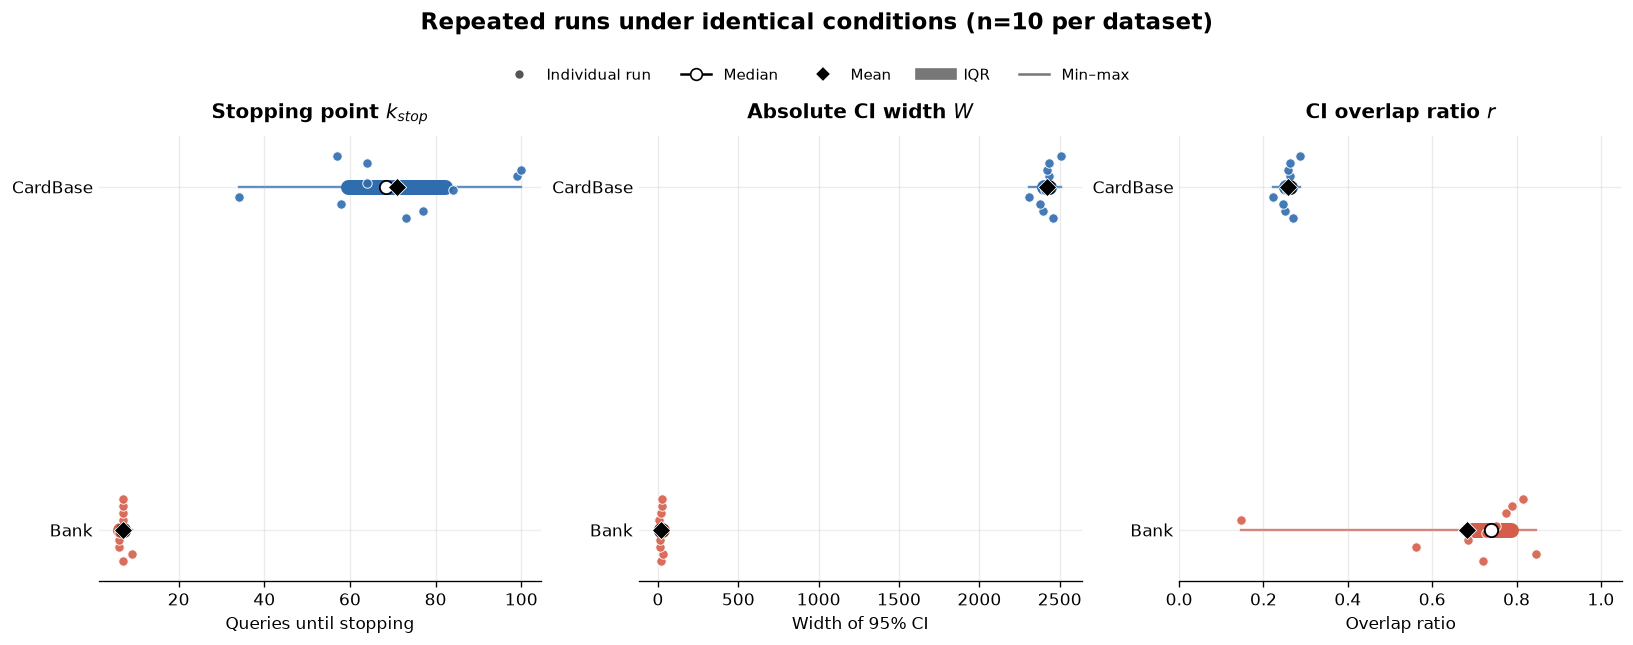

In [8]:
plot_repeated_distributions(final_results);

## Figure 2: 대표 시행의 수렴 과정과 수렴점 오버랩

각 데이터셋에서 `k_stop`이 중앙값에 가장 가까운 시행을 대표 시행으로 선택한다. 이는 임의로 가장 좋은 시행을 고르는 것이 아니라, 반복 결과의 전형적인 시행을 보여주기 위한 것이다.

In [16]:
def choose_representative(final_results, dataset):
    g = final_results[
        final_results["dataset"] == dataset
    ].copy()

    target = g["k_stop"].median()
    return g.iloc[(g["k_stop"] - target).abs().argmin()]


def plot_representative(final_results, trajectories, dataset, save=None):
    # 대표 시행 선택
    f = choose_representative(final_results, dataset)

    # 해당 대표 시행의 전체 질의 궤적 선택
    h = trajectories[
        (trajectories["dataset"] == dataset) &
        (trajectories["rep"] == f["rep"])
    ].copy()

    # 핵심 수정:
    # final_results에 adj_center 열이 없어도 직접 계산
    adj_center = f["mean"] - f["delta"]

    fig, (ax0, ax1) = plt.subplots(
        2,
        1,
        figsize=(11, 7),
        gridspec_kw={"height_ratios": [1.2, 1]},
        constrained_layout=True
    )

    blue = "#2166ac"
    orange = "#d6604d"
    green = "#1a9850"
    purple = "#762a83"
    gray = "#666666"

    # =====================================================
    # 위 패널: 대표 시행의 질의 누적 과정
    # =====================================================
    hh = h[h["k"] >= 2]

    ax0.scatter(
        h["k"],
        h["response"],
        color=gray,
        s=16,
        alpha=0.65,
        label="Noisy response"
    )

    ax0.plot(
        h["k"],
        h["mean"],
        color=blue,
        lw=1.8,
        label="Cumulative mean"
    )

    ax0.fill_between(
        hh["k"].to_numpy(),
        hh["ci_lo"].to_numpy(),
        hh["ci_hi"].to_numpy(),
        color=blue,
        alpha=0.13,
        label="95% CI"
    )

    ax0.axhline(
        f["true_mean"],
        color=green,
        ls="--",
        label="True mean"
    )

    ax0.axvline(
        f["k_stop"],
        color="black",
        ls=":",
        label=f"Stop k={int(f['k_stop'])}"
    )

    ax0.set_title(
        f"{dataset}: representative run "
        f"(rep={int(f['rep'])}, seed={int(f['seed'])})"
    )
    ax0.set_xlabel("Query count k")
    ax0.set_ylabel("Query output")
    ax0.legend(frameon=False, ncol=4)

    # =====================================================
    # 아래 패널: 수렴 시점의 신뢰구간 겹침
    # =====================================================
    y = np.zeros(len(h)) + 0.03 * np.sin(
        np.arange(len(h)) * 2.2
    )

    # 실제 질의 응답값
    ax1.scatter(
        h["response"],
        y,
        color=gray,
        s=22,
        alpha=0.7,
        label="Responses"
    )

    # 실제 데이터셋 평균
    ax1.axvline(
        f["true_mean"],
        color=green,
        ls="--",
        label="True mean"
    )

    # 수렴 시점 누적 평균
    ax1.axvline(
        f["mean"],
        color=blue,
        lw=1.2,
        label="Cumulative mean at stop"
    )

    # 민감도만큼 아래로 이동한 인접 데이터베이스 중심
    # 기존의 f["adj_center"]를 사용하지 않는 것이 핵심
    ax1.axvline(
        adj_center,
        color=orange,
        lw=1.2,
        label="Shifted center"
    )

    # 원본 데이터베이스의 95% 신뢰구간
    ax1.plot(
        [f["ci_lo"], f["ci_hi"]],
        [0.60, 0.60],
        color=blue,
        lw=9,
        solid_capstyle="round",
        label="Original 95% CI"
    )

    # 인접 데이터베이스의 95% 신뢰구간
    ax1.plot(
        [f["adj_ci_lo"], f["adj_ci_hi"]],
        [0.35, 0.35],
        color=orange,
        lw=9,
        solid_capstyle="round",
        label="Shifted adjacent CI"
    )

    # 신뢰구간 겹침 영역
    if f["overlap_width"] > 0:
        ax1.plot(
            [f["overlap_lo"], f["overlap_hi"]],
            [0.475, 0.475],
            color=purple,
            lw=11,
            solid_capstyle="round",
            label="CI overlap"
        )

    ax1.set_yticks(
        [0, 0.35, 0.475, 0.60],
        [
            "Responses",
            "Adjacent CI",
            "Overlap",
            "Original CI"
        ]
    )

    ax1.set_xlabel("Query output")
    ax1.set_title(
        "Stopping-point confidence-interval comparison"
    )

    # 수렴점 결과 표시
    note = (
        f"k_stop={int(f['k_stop'])} | "
        f"W={f['width']:,.1f} | "
        f"relative width={f['relative_width']:.4f}\n"
        f"delta={f['delta']:,.1f} | "
        f"overlap ratio={f['overlap_ratio']:.4f}"
    )

    ax1.text(
        0.99,
        1.03,
        note,
        transform=ax1.transAxes,
        ha="right",
        va="bottom",
        bbox=dict(
            boxstyle="round,pad=.3",
            facecolor="white",
            edgecolor="#aaa"
        )
    )

    ax1.legend(
        frameon=False,
        ncol=3,
        loc="upper left",
        bbox_to_anchor=(0, -0.22)
    )

    if save is not None:
        fig.savefig(
            save,
            dpi=300,
            bbox_inches="tight"
        )

    plt.show()
    return fig

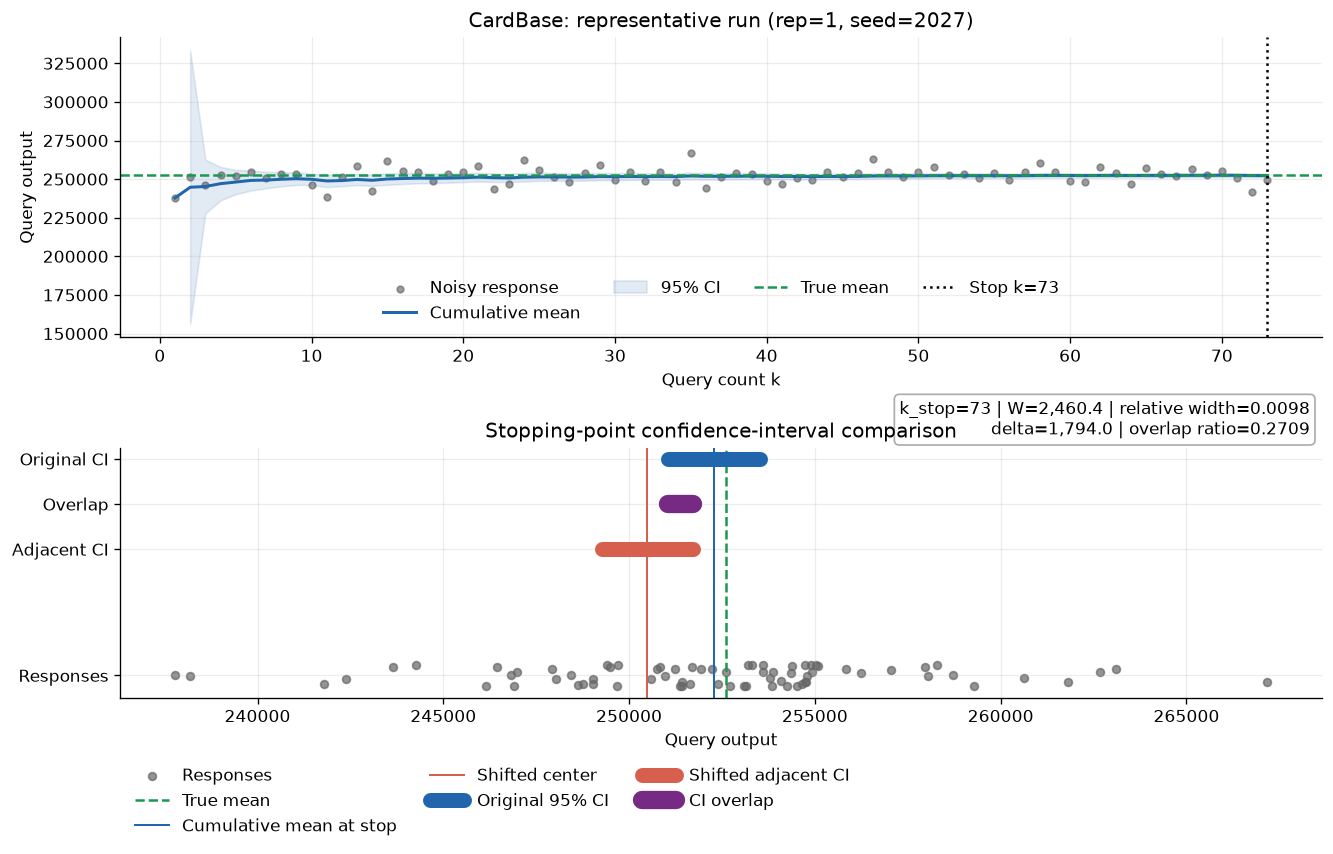

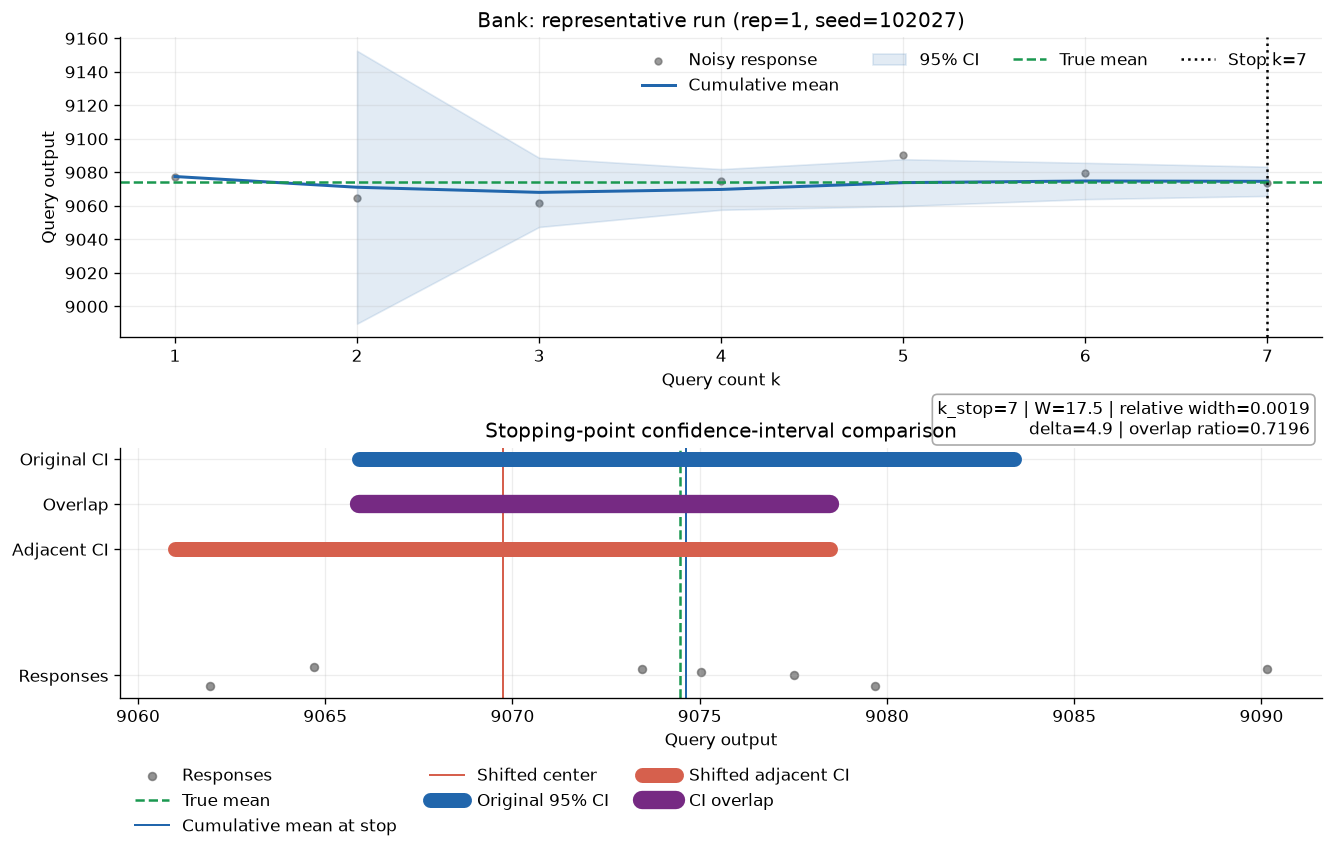

In [17]:
for name in DATA:
    plot_representative(
        final_results,
        trajectories,
        name,
        OUTPUT_DIR / f"figure_representative_{name}.png"
    )

## 해석 시 주의

- `k_stop`, `W`, `r`의 평균·중앙값·최소–최대는 **동일 조건에서 라플라스 노이즈 시드만 바꾼 반복 시행의 경험적 요약**이다.
- 최소–최대는 10회 반복 결과의 범위이며, 모집단의 95% 신뢰구간이 아니다.
- Figure 1에서 점들이 데이터셋 간 차이를 반복적으로 보여주는지 확인하고, Figure 2는 전형적인 한 시행의 계산 흐름을 설명한다.
- 모든 반복 시행은 원 논문의 중단 규칙으로 자체 `k_stop`을 찾으며, `maxq`는 정상 종료를 방해하지 않도록 둔 안전 상한이다.

In [24]:
# Bank에서 오버랩 비율이 가장 낮은 시행 확인
bank_outlier = (
    final_results[final_results["dataset"] == "Bank"]
    .sort_values("overlap_ratio")
    .iloc[0]
)

bank_outlier[
    [
        "dataset", "rep", "seed",
        "k_stop", "eps_total",
        "mean", "true_mean",
        "width", "relative_width",
        "delta", "overlap_width",
        "overlap_ratio"
    ]
]

dataset                  Bank
rep                         7
seed                   102033
k_stop                      7
eps_total                 3.5
mean               9073.42413
true_mean         9074.479537
width                5.741654
relative_width       0.000633
delta                4.904656
overlap_width        0.836998
overlap_ratio        0.145776
Name: 16, dtype: object

In [25]:
def plot_specific_run(final_results, trajectories, dataset, rep, save=None):
    f = final_results[
        (final_results["dataset"] == dataset) &
        (final_results["rep"] == rep)
    ].iloc[0]

    h = trajectories[
        (trajectories["dataset"] == dataset) &
        (trajectories["rep"] == rep)
    ].copy()

    fig, (ax0, ax1) = plt.subplots(
        2, 1,
        figsize=(11, 7),
        gridspec_kw={"height_ratios": [1.2, 1]},
        constrained_layout=True
    )

    blue = "#2166ac"
    orange = "#d6604d"
    green = "#1a9850"
    purple = "#762a83"
    gray = "#666666"

    # 위 패널: 해당 시행의 수렴 과정
    hh = h[h["k"] >= 2]

    ax0.scatter(
        h["k"], h["response"],
        color=gray, s=18, alpha=.7,
        label="Noisy response"
    )

    ax0.plot(
        h["k"], h["mean"],
        color=blue, lw=1.8,
        label="Cumulative mean"
    )

    ax0.fill_between(
        hh["k"].to_numpy(),
        hh["ci_lo"].to_numpy(),
        hh["ci_hi"].to_numpy(),
        color=blue, alpha=.14,
        label="95% CI"
    )

    ax0.axhline(
        f["true_mean"],
        color=green, ls="--", lw=1.4,
        label="True mean"
    )

    ax0.axvline(
        f["k_stop"],
        color="black", ls=":", lw=1.4,
        label=f"Stop k={int(f['k_stop'])}"
    )

    ax0.set_title(
        f"{dataset}: lowest-overlap run "
        f"(rep={int(f['rep'])}, seed={int(f['seed'])})"
    )
    ax0.set_xlabel("Query count k")
    ax0.set_ylabel("Query output")
    ax0.legend(frameon=False, ncol=4)

    # 아래 패널: 수렴 시점의 원본/인접 신뢰구간
    y = np.zeros(len(h)) + .03 * np.sin(np.arange(len(h)) * 2.2)

    ax1.scatter(
        h["response"], y,
        color=gray, s=22, alpha=.7,
        label="Responses"
    )

    ax1.axvline(
        f["true_mean"],
        color=green, ls="--", lw=1.4,
        label="True mean"
    )

    ax1.axvline(
        f["mean"],
        color=blue, lw=1.2,
        label="Cumulative mean at stop"
    )

    # ax1.axvline(
    #     f["adj_center"],
    #     color=orange, lw=1.2,
    #     label="Shifted center"
    # )
    adj_center = f["mean"] - f["delta"]

    ax1.axvline(
        adj_center,
        color=orange,
        lw=1.2,
        label="Shifted center"
    )


    ax1.plot(
        [f["ci_lo"], f["ci_hi"]], [.60, .60],
        color=blue, lw=9,
        solid_capstyle="round",
        label="Original 95% CI"
    )

    ax1.plot(
        [f["adj_ci_lo"], f["adj_ci_hi"]], [.35, .35],
        color=orange, lw=9,
        solid_capstyle="round",
        label="Shifted adjacent CI"
    )

    if f["overlap_width"] > 0:
        ax1.plot(
            [f["overlap_lo"], f["overlap_hi"]], [.475, .475],
            color=purple, lw=11,
            solid_capstyle="round",
            label="CI overlap"
        )

    ax1.set_yticks(
        [0, .35, .475, .60],
        ["Responses", "Adjacent CI", "Overlap", "Original CI"]
    )
    ax1.set_xlabel("Query output")
    ax1.set_title("Lowest-overlap stopping-point comparison")

    note = (
        f"rep={int(f['rep'])}, seed={int(f['seed'])}\n"
        f"k_stop={int(f['k_stop'])} | "
        f"W={f['width']:,.1f} | "
        f"relative width={f['relative_width']:.4f}\n"
        f"Δ={f['delta']:,.1f} | "
        f"overlap ratio={f['overlap_ratio']:.4f}"
    )

    ax1.text(
        .99, 1.03, note,
        transform=ax1.transAxes,
        ha="right", va="bottom",
        bbox=dict(
            boxstyle="round,pad=.3",
            facecolor="white",
            edgecolor="#aaa"
        )
    )

    ax1.legend(
        frameon=False,
        ncol=3,
        loc="upper left",
        bbox_to_anchor=(0, -.22)
    )

    if save:
        fig.savefig(save, dpi=300, bbox_inches="tight")

    plt.show()
    return fig

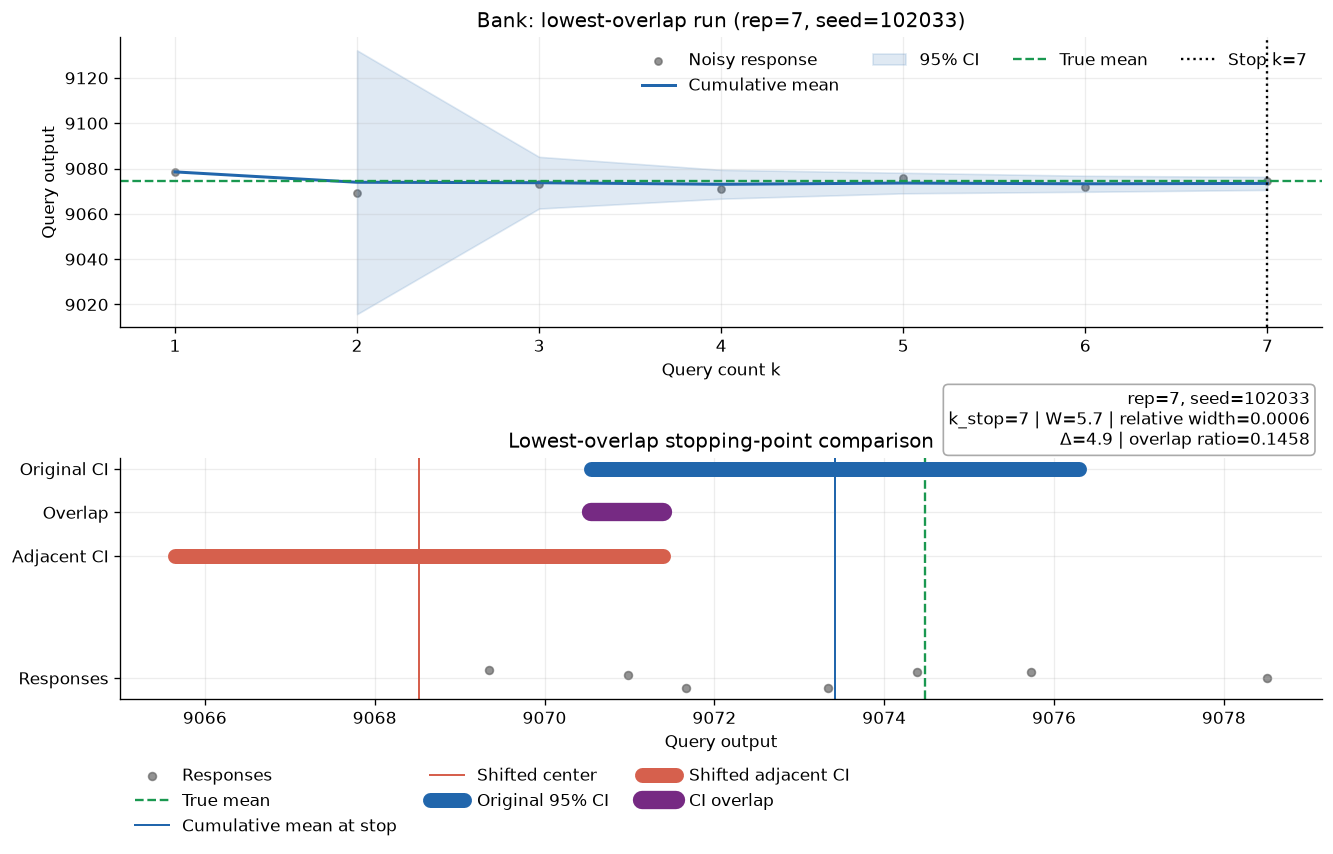

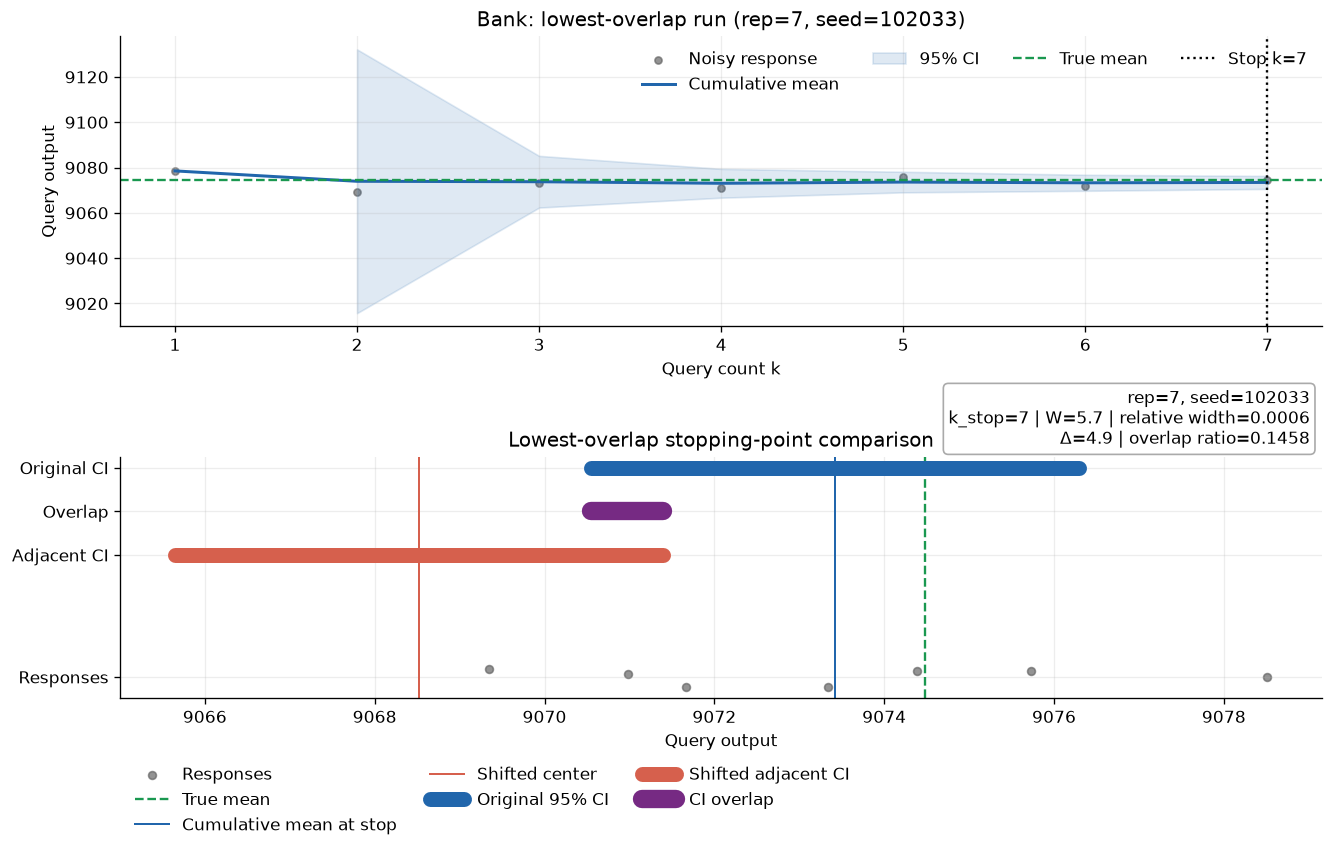

In [26]:
plot_specific_run(
    final_results,
    trajectories,
    dataset="Bank",
    rep=int(bank_outlier["rep"]),
    save=OUTPUT_DIR / "figure_bank_low_overlap.png"
)

Bank lowest-overlap run
rep                      7
seed                102033
k_stop                   7
width             5.741654
relative_width    0.000633
overlap_ratio     0.145776
Name: 16, dtype: object

CardBase same repetition number
rep                         7
seed                     2033
k_stop                     99
width             2431.322059
relative_width       0.009607
overlap_ratio         0.26213
Name: 6, dtype: object


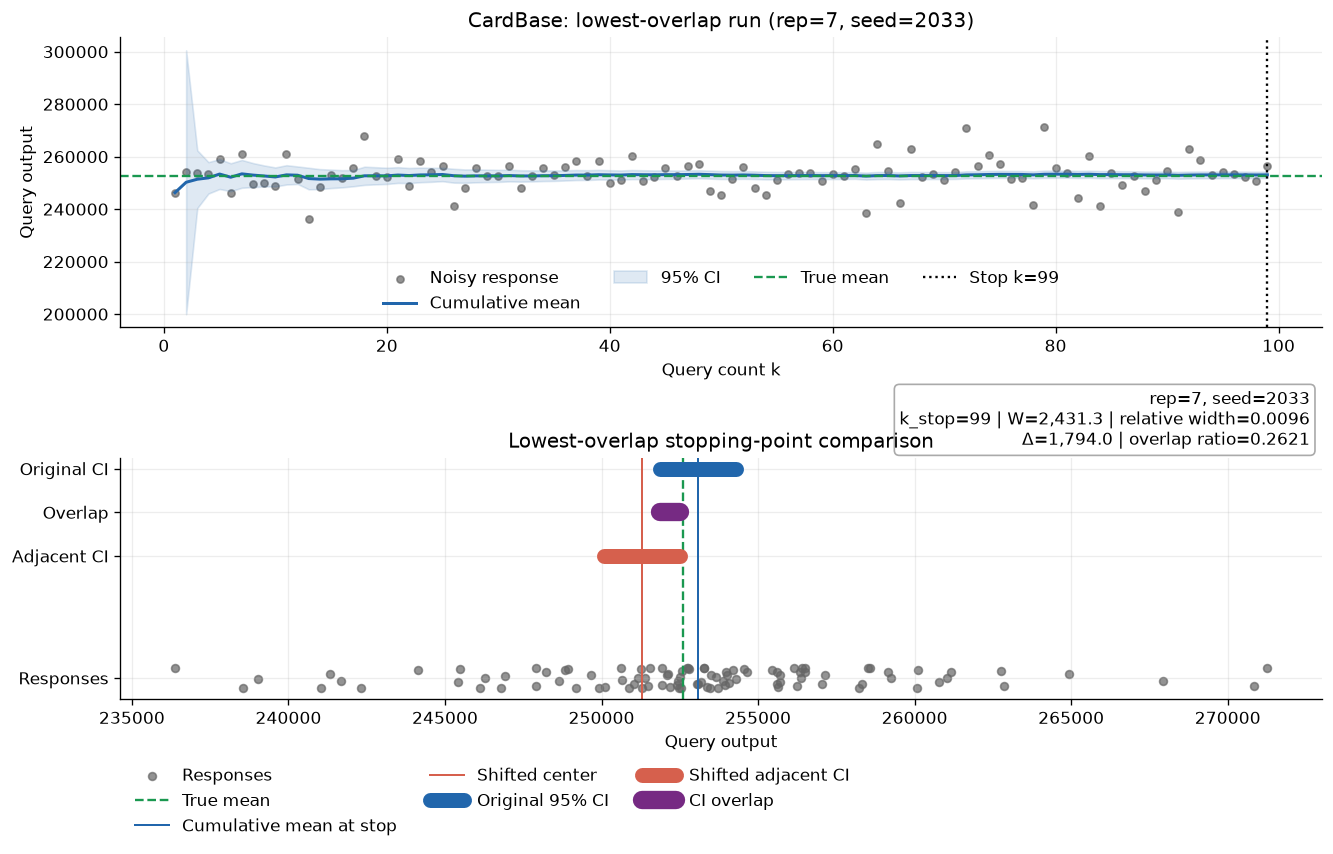

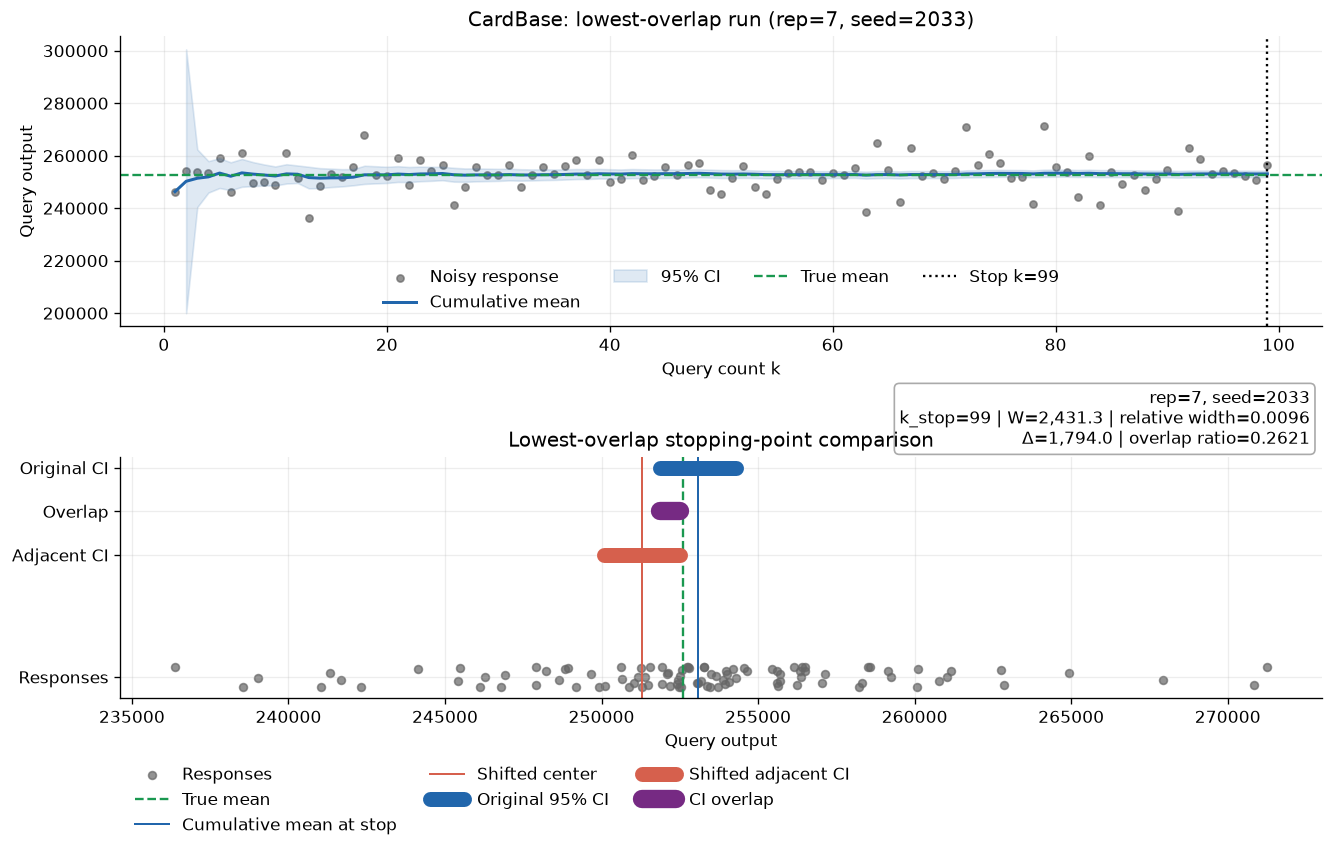

In [ ]:
cardbase_same_rep = final_results[
    (final_results["dataset"] == "CardBase") &
    (final_results["rep"] == bank_outlier["rep"])
].iloc[0]

print("Bank lowest-overlap run")
print(bank_outlier[
    ["rep", "seed", "k_stop", "width",
     "relative_width", "overlap_ratio"]
])

print("\nCardBase same repetition number")
print(cardbase_same_rep[
    ["rep", "seed", "k_stop", "width",
     "relative_width", "overlap_ratio"]
])

plot_specific_run(
    final_results,
    trajectories,
    dataset="CardBase",
    rep=int(bank_outlier["rep"]),
    save=OUTPUT_DIR / "figure_cardbase_matched_rep.png"
);